# DecisionTree pipeline

A Decision Tree asks a sequence of threshold questions on single variables (is PURCHASES > 812? is BALANCE > 1000?) until each leaf is pure. Fully interpretable, but a deep tree overfits on its own.

One model, one notebook: the full flow (load → split → SMOTE → `Pipeline` → evaluate) with **DecisionTree** as the classifier. Tuned with GridSearchCV in `classification.ipynb`: `max_depth=None` (default — grows until pure).

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE

df = pd.read_csv("../data/processed/df_clean_clustered.csv")
feats = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES",
         "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS"]
X = df[feats]
y = df["target"]


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0, stratify=y)

smote = SMOTE(random_state=0)
print("train before SMOTE:")
print(y_train.value_counts().to_string())
print()

X_train, y_train = smote.fit_resample(X_train, y_train)

print("train after SMOTE:")
print(y_train.value_counts().to_string())


train before SMOTE:
target
Premium Active Spenders       2714
Low-Activity / Low-Balance    2502
Cash-Advance Dependent        1943

train after SMOTE:
target
Low-Activity / Low-Balance    2714
Premium Active Spenders       2714
Cash-Advance Dependent        2714


In [3]:
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", DecisionTreeClassifier(random_state=0)),
])

pipeline.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['Cash-Advance Dependent','Low-Activity / Low-Balance', 'Premium Active Spenders']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['BALANCE','PURCHASES','ONEOFF_PURCHASES',...,'CASH_ADVANCE', 'CREDIT_LIMIT','PAYMENTS']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [4]:
pred = pipeline.predict(X_test)
print("accuracy: ", round(accuracy_score(y_test, pred), 3))
print("precision:", round(precision_score(y_test, pred, average="weighted"), 3))
print("recall:   ", round(recall_score(y_test, pred, average="weighted"), 3))
print("f1:       ", round(f1_score(y_test, pred, average="weighted"), 3))


accuracy:  0.942
precision: 0.943
recall:    0.942
f1:        0.942


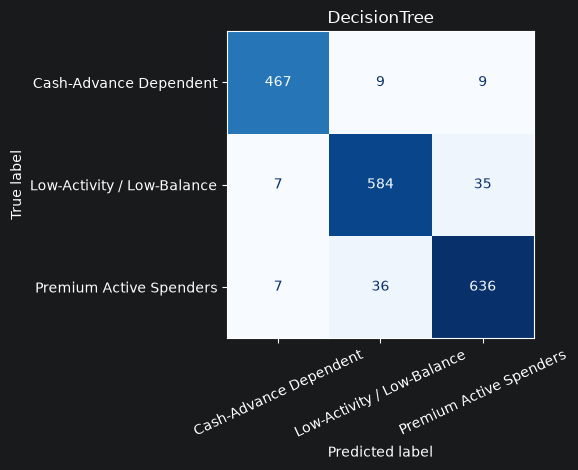

In [5]:
ConfusionMatrixDisplay.from_estimator(
    pipeline, X_test, y_test, cmap="Blues", xticks_rotation=25, colorbar=False)
plt.title("DecisionTree")
plt.tight_layout()
plt.show()


In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
folds = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="f1_weighted")
print("fold F1:", np.round(folds, 3))
print(f"mean {folds.mean():.3f}   std {folds.std():.3f}")


fold F1: [0.944 0.945 0.937 0.935 0.949]
mean 0.942   std 0.005


### Result

Test F1 **≈ 0.94** — strong, but a single tree is unstable: change the data slightly and the splits move. The Random Forest fixes this by averaging many trees.

The side-by-side comparison of all four models (confusion matrices, CV boxplots, GridSearch, feature importance) lives in `classification.ipynb`.